Trong bối cảnh hiện nay, hoạt động tín dụng đóng vai trò quan trọng trong hệ thống ngân hàng thương mại, vừa tạo nguồn thu chủ yếu từ lãi vay, vừa hỗ trợ cá nhân và doanh nghiệp tiếp cận vốn. Tuy nhiên, đi kèm với hoạt động cho vay là rủi ro khách hàng không thể hoàn trả nợ đúng hạn, hay còn gọi là vỡ nợ (loan default), gây ảnh hưởng đến hiệu quả kinh doanh và sự ổn định của ngân hàng. Với sự phát triển của dữ liệu lớn và Machine Learning, việc xây dựng các mô hình dự đoán khả năng vỡ nợ đã trở thành một hướng tiếp cận quan trọng, giúp ngân hàng nâng cao hiệu quả quản trị rủi ro và hỗ trợ ra quyết định tín dụng. Xuất phát từ thực tiễn đó, nhóm lựa chọn đề tài **“Dự đoán khả năng vỡ nợ của khách hàng”** nhằm phân tích và xây dựng mô hình dự đoán dựa trên dữ liệu lịch sử tín dụng.

##### **Mục tiêu:** Dựa trên tập dữ liệu Loan Default Dataset, tiến hành phân tích và xây dựng mô hình để:

* Xác định các yếu tố ảnh hưởng đến khả năng khách hàng vỡ nợ.

* Dự đoán trạng thái vỡ nợ của khách hàng bằng các mô hình học máy.

#### **Thành viên thực hiện**:
* Võ Thị Vân Thư
* Nguyễn Đoàn Nguyệt Hà
* Nguyễn Thị Yến Như
* Đặng Hồng Nguyệt
* Nguyễn Bùi Minh Hằng
* Võ Hồng Quyên

##**1. Import thư viện**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.utils.class_weight import compute_class_weight
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve, confusion_matrix

import shap
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline

##**2. Load data**

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
df = pd.read_csv("/content/drive/MyDrive/ML/Loan_default.csv")

In [7]:
# Số dòng và số cột ban đầu của tập dữ liệu
print(f"Số lượng dòng: {df.shape[0]}")
print(f"Số lượng cột: {df.shape[1]}")

Số lượng dòng: 255347
Số lượng cột: 18


In [ ]:
df.head()

,LoanID,Age,Income,LoanAmount,CreditScore,MonthsEmployed,NumCreditLines,InterestRate,LoanTerm,DTIRatio,Education,EmploymentType,MaritalStatus,HasMortgage,HasDependents,LoanPurpose,HasCoSigner,Default
0,I38PQUQS96,56,85994,50587,520,80,4,15.23,36,0.44,Bachelor's,Full-time,Divorced,Yes,Yes,Other,Yes,0
1,HPSK72WA7R,69,50432,124440,458,15,1,4.81,60,0.68,Master's,Full-time,Married,No,No,Other,Yes,0
2,C1OZ6DPJ8Y,46,84208,129188,451,26,3,21.17,24,0.31,Master's,Unemployed,Divorced,Yes,Yes,Auto,No,1
3,V2KKSFM3UN,32,31713,44799,743,0,3,7.07,24,0.23,High School,Full-time,Married,No,No,Business,No,0
4,EY08JDHTZP,60,20437,9139,633,8,4,6.51,48,0.73,Bachelor's,Unemployed,Divorced,No,Yes,Auto,No,0


In [8]:
# Kiểm tra thông tin tổng quát
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-null  object 
 17  Default   

##**3. Khám phá dữ liệu ban đầu (EDA)**

In [9]:
# Kiểm tra số lượng giá trị thiếu trên từng cột
print("\nThống kê giá trị thiếu:")
print(df.isnull().sum())


Thống kê giá trị thiếu:
LoanID            0
Age               0
Income            0
LoanAmount        0
CreditScore       0
MonthsEmployed    0
NumCreditLines    0
InterestRate      0
LoanTerm          0
DTIRatio          0
Education         0
EmploymentType    0
MaritalStatus     0
HasMortgage       0
HasDependents     0
LoanPurpose       0
HasCoSigner       0
Default           0
dtype: int64


In [10]:
# Kiểm tra số lượng giá trị bị trùng lặp
df.duplicated().sum()

np.int64(0)

Số lượng khách hàng từng nhóm:
Default
0    225694
1     29653
Name: count, dtype: int64

Tỷ lệ phần trăm (%):
Default
0    88.387175
1    11.612825
Name: proportion, dtype: float64


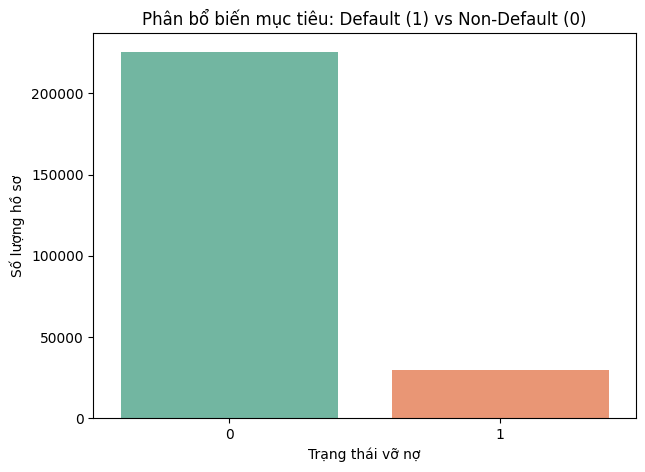

In [11]:
# Tỷ lệ biến mục tiêu
# Tính toán tỷ lệ phần trăm các lớp
target_counts = df['Default'].value_counts()
target_percent = df['Default'].value_counts(normalize=True) * 100

print(f"Số lượng khách hàng từng nhóm:\n{target_counts}")
print(f"\nTỷ lệ phần trăm (%):\n{target_percent}")

# Trực quan hóa
plt.figure(figsize=(7, 5))
sns.countplot(x='Default', data=df, palette='Set2')
plt.title('Phân bổ biến mục tiêu: Default (1) vs Non-Default (0)')
plt.xlabel('Trạng thái vỡ nợ')
plt.ylabel('Số lượng hồ sơ')
plt.show()

## **4. Tiền xử lý dữ liệu**



**4.1. Xóa cột không cần thiết**

In [12]:
# Drop cột LoanID
df = df.drop(columns = ['LoanID'])

In [13]:
print(f"Số lượng cột: {df.shape[1]}")

Số lượng cột: 17


In [14]:
df.columns

Index(['Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed',
       'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education',
       'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents',
       'LoanPurpose', 'HasCoSigner', 'Default'],
      dtype='object')

Sau khi xóa cột không mang ý nghĩa dự đoán thì bộ dữ liệu còn 17 cột như trên

**4.2. Mã hóa biến phân loại (One-Hot Encoding)**

In [15]:
categorical_cols = df.select_dtypes(include=['object']).columns
df_encoded = pd.get_dummies(df, columns=categorical_cols, drop_first=True)

mapping = []

for col in categorical_cols:
    new_cols = [c for c in df_encoded.columns if c.startswith(col + "_")]
    mapping.append({
        "Cột gốc": col,
        "Các cột sau khi One-Hot Encoding": ", ".join(new_cols)
    })

mapping_df = pd.DataFrame(mapping)

mapping_df

,Cột gốc,Các cột sau khi One-Hot Encoding
0,Education,"Education_High School, Education_Master's, Edu..."
1,EmploymentType,"EmploymentType_Part-time, EmploymentType_Self-..."
2,MaritalStatus,"MaritalStatus_Married, MaritalStatus_Single"
3,HasMortgage,HasMortgage_Yes
4,HasDependents,HasDependents_Yes
5,LoanPurpose,"LoanPurpose_Business, LoanPurpose_Education, L..."
6,HasCoSigner,HasCoSigner_Yes


In [ ]:
rows, cols = df_encoded.shape
print(f"Số dòng sau xử lý: {rows}")
print(f"Số cột sau xử lý: {cols}")

Số dòng sau xử lý: 255347
Số cột sau xử lý: 25


Sau khi áp dụng One-Hot Encoding cho các biến phân loại, số lượng cột tăng từ 17 lên 25 do mỗi giá trị trong các biến này được tách thành một cột nhị phân riêng, giúp dữ liệu phù hợp hơn cho mô hình học máy.

**4.3. Chia tập dữ liệu**

In [16]:
X = df_encoded.drop('Default', axis=1)
y = df_encoded['Default']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y          # giữ đúng tỷ lệ lớp
)

Tập dữ liệu được chia thành 80% huấn luyện và 20% kiểm tra, đồng thời giữ nguyên tỷ lệ các lớp của biến mục tiêu nhằm đảm bảo đánh giá mô hình khách quan.

**4.4. Chuẩn hóa dữ liệu số (Standardization)**

In [17]:
# Xác định cột số (không bao gồm biến mục tiêu)
numeric_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

scaler = StandardScaler()

# Fit scaler trên tập train
X_train[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

# Transform trên tập test
X_test[numeric_cols] = scaler.transform(X_test[numeric_cols])

Dữ liệu số được chuẩn hóa bằng StandardScaler sau khi chia train–test, trong đó scaler được fit trên tập huấn luyện và áp dụng cho tập kiểm tra nhằm tránh rò rỉ dữ liệu và cải thiện hiệu quả mô hình.

**4.5. Xử lý mất cân bằng dữ liệu**

In [18]:
# Tính trọng số lớp dựa trên y_train
class_weights = compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

# Chuyển về dạng dictionary để dùng cho mô hình
class_weights = dict(zip(np.unique(y_train), class_weights))

print("Class weights:", class_weights)

Class weights: {np.int64(0): np.float64(0.5656918944365983), np.int64(1): np.float64(4.30564454936346)}


Việc tính trọng số lớp giúp các mô hình học máy xử lý tốt hơn bài toán mất cân bằng lớp. Các mô hình hỗ trợ cơ chế trọng số sẽ chú trọng hơn đến nhóm khách hàng vỡ nợ (Default = 1), qua đó cải thiện khả năng phát hiện rủi ro tín dụng.

## **5. Xây dựng, huấn luyện mô hình và Dự đoán**

**5.1. Logistic Regression**

In [20]:
# Khởi tạo mô hình
lr_model = LogisticRegression(class_weight= class_weights, max_iter=1000)

# Huấn luyện mô hình
lr_model.fit(X_train, y_train)

# Dự đoán mô hình
y_pred_lr = lr_model.predict(X_test)

# Xác xuất dự đoán cho lớp 1 (vỡ nợ)
lr_proba = lr_model.predict_proba(X_test)[:,1]

print("LOGISTIC REGRESSION")

# Tạo bảng so sánh thực tế và dự đoán
bang_ket_qua = pd.DataFrame({
    "Thực tế": y_test.values,
    "Dự đoán": y_pred_lr,
    "Xác suất vỡ nợ": lr_proba
})
# Tạo bảng so sánh 10 mẫu đầu tiên trong tập test
print("\nSố mẫu test:", len(X_test))
print("\nBẢNG SO SÁNH THỰC TẾ VỚI DỰ ĐOÁN:")
print(bang_ket_qua.head(10))

print("\nMa trận nhầm lẫn:\n", confusion_matrix(y_test, y_pred_lr))
print("\nBáo cáo phân loại:\n",classification_report(y_test, y_pred_lr))

LOGISTIC REGRESSION

Số mẫu test: 51070

BẢNG SO SÁNH THỰC TẾ VỚI DỰ ĐOÁN:
   Thực tế  Dự đoán  Xác suất vỡ nợ
0        0        0        0.186358
1        0        0        0.140203
2        0        0        0.378181
3        0        1        0.569233
4        0        0        0.407138
5        0        0        0.068914
6        0        1        0.804479
7        0        0        0.368180
8        1        1        0.795809
9        0        1        0.593022

Ma trận nhầm lẫn:
 [[30393 14746]
 [ 1781  4150]]

Báo cáo phân loại:
               precision    recall  f1-score   support

           0       0.94      0.67      0.79     45139
           1       0.22      0.70      0.33      5931

    accuracy                           0.68     51070
   macro avg       0.58      0.69      0.56     51070
weighted avg       0.86      0.68      0.73     51070



**Ma trận nhầm lẫn**

TN = 30391, số lượng dự đoán đúng khách hàng thanh toán đúng hạn.

FP = 14748, số lượng dự đoán nhầm khách hàng vỡ nợ.

FN = 1782, số lượng bỏ sót khách hàng vỡ nợ.

TP = 4149, số lượng dự đoán đúng khách hàng vỡ nợ.

-> Mô hình ưu tiên phát hiện vỡ nợ, nhưng đánh đổi bằng việc tăng mạnh dự đoán sai ở lớp vỡ nợ.

**Báo cáo phân loại**

Lớp 0 (khách hàng thanh toán đúng hạn):
- Precision = 0,94 khi dự đoán khách hàng thanh toán đúng hạn rất đáng tin cậy.
- Recall = 0,67 chỉ nhận diện được 67% khách hàng thanh toán đúng hạn.
- F1-score = 0,79 Hiệu quả tổng thể ở mức khá.
Lớp 1 (vỡ nợ):
- Precision = 0,22 khi dự đoán vỡ nợ thì độ chính xác thấp, nhiều cảnh báo sai.
- Recall = 0,70 phát hiện được 70% khách hàng vỡ nợ.
- F1-score = 0,33 chưa cần bằng tốt giữa precision.

Accuracy = 0.68: Không phản ánh đúng chất lượng do dữ liệu mất cân bằng.

Macro avg thấp, mô hình hoạt động không đều giữa hai lớp.

Weighted avg cao, bị chi phối bởi lớp 0 (chiếm đa số).

**Kết luận:** Logistic Regression phù hợp trong bối cảnh ưu tiên phát hiện rủi ro tín dụng, tuy nhiên cần tiếp tục cải thiện để giảm tỷ lệ dự đoán sai đối với lớp vỡ nợ.


**5.2. Random Forest**

In [21]:
# Khởi tạo mô hình
rf_model = RandomForestClassifier(
    n_estimators= 200,
    max_depth= 12,
    random_state=42,
    class_weight = class_weights
)

# Huấn luyện mô hình
rf_model.fit(X_train, y_train)

# Dự đoán mô hình
y_pred_rf = rf_model.predict(X_test)

# Xác xuất dự đoán cho lớp 1 (vỡ nợ)
rf_proba = rf_model.predict_proba(X_test)[:,1]

print("RANDOM FOREST")

# Tạo bảng so sánh
bang_ket_qua = pd.DataFrame({
    "Thực tế": y_test.values,
    "Dự đoán": y_pred_rf,
    "Xác suất vỡ nợ": rf_proba
})
# Tạo bảng so sánh 10 mẫu đầu tiên trong tập test
print("\nSố mẫu test:", len(X_test))
print("\nBẢNG SO SÁNH THỰC TẾ VỚI DỰ ĐOÁN:")
print(bang_ket_qua.head(10))

print("\nMa trận nhầm lẫn:\n", confusion_matrix(y_test, y_pred_rf))
print("\nBáo cáo phân loại:\n", classification_report(y_test, y_pred_rf))

RANDOM FOREST

Số mẫu test: 51070

BẢNG SO SÁNH THỰC TẾ VỚI DỰ ĐOÁN:
   Thực tế  Dự đoán  Xác suất vỡ nợ
0        0        0        0.236015
1        0        0        0.203323
2        0        0        0.296330
3        0        0        0.366880
4        0        0        0.286104
5        0        0        0.112797
6        0        1        0.668562
7        0        0        0.273990
8        1        1        0.609154
9        0        1        0.532128

Ma trận nhầm lẫn:
 [[36417  8722]
 [ 2676  3255]]

Báo cáo phân loại:
               precision    recall  f1-score   support

           0       0.93      0.81      0.86     45139
           1       0.27      0.55      0.36      5931

    accuracy                           0.78     51070
   macro avg       0.60      0.68      0.61     51070
weighted avg       0.85      0.78      0.81     51070



**Ma trận nhầm lẫn:**

TN = 36419: Số lượng khách hàng thanh toán đúng hạn được dự đoán đúng, khá cao.

FP = 8720: Số lượng khách hàng thanh toán đúng hạn bị dự đoán nhầm là vỡ nợ, ít hơn Logistic Regression, nghĩa là giảm cảnh báo sai.

FN = 2677: Số lượng khách hàng vỡ nợ bị bỏ sót, cao hơn Logistic Regression, nghĩa là mô hình bỏ sót nhiều hơn.

TP = 3254: Số lượng khách hàng vỡ nợ được dự đoán đúng, thấp hơn Logistic Regression, nên khả năng phát hiện rủi ro giảm.


**Báo cáo phân loại**

Lớp 0 (khách hàng thanh toán đúng hạn):

- Precision = 0.93, khi dự đoán khách hàng thanh toán đúng hạn thì khá đáng tin cậy.
- Recall = 0.81, nhận diện được 81% khách hàng thanh toán đúng hạn, cải thiện so với Logistic Regression.
- F1-score = 0.86, hiệu quả tốt, vì lớp này chiếm đa số.

Lớp 1 (vỡ nợ):

- Precision = 0.27, khi dự đoán vỡ nợ thì vẫn nhiều cảnh báo sai, thấp nhưng cao hơn Logistic Regression.
- Recall = 0.55, chỉ phát hiện được 55% khách hàng vỡ nợ, giảm so với Logistic Regression, nghĩa là bỏ sót nhiều rủi ro hơn.
- F1-score = 0.36, cải thiện nhẹ so với Logistic Regression, nhưng vẫn chưa cao.
Mô hình giảm cảnh báo sai, nhưng khả năng phát hiện khách hàng vỡ nợ chưa tốt.

Accuracy = 0.78, nhìn có vẻ tốt nhưng cũng không phản ánh đúng chất lượng do dữ liệu mất cân bằng.

Macro avg thấp,  mô hình hoạt động không đều giữa hai lớp.

Weighted avg cao, bị chi phối bởi lớp 0 (khách hàng thanh toán đúng hạn), nên nhìn có vẻ cao hơn thực tế hiệu quả lớp rủi ro.


**5.3. XGBoost**

In [22]:
# Tính toán tỷ lệ cân bằng
count_non_default = np.sum(y_train == 0)
count_default = np.sum(y_train == 1)
scale_ratio = count_non_default / count_default

# Khởi tạo mô hình
xgb_model = XGBClassifier(
    n_estimators=200,
    learning_rate=0.1,
    max_depth=6,
    scale_pos_weight=scale_ratio,
    random_state=42,
    use_label_encoder=False,
    eval_metric='logloss'
)

# Huấn luyện mô hình
xgb_model.fit(X_train, y_train)

# Dự đoán mô hình
y_pred_xgb = xgb_model.predict(X_test)

# Xác suất dự đoán cho lớp 1 (vỡ nợ)
xgb_proba = xgb_model.predict_proba(X_test)[:,1]

print("XGBOOST CLASSIFICATION")

# Tạo bảng so sánh
bang_ket_qua_xgb = pd.DataFrame({
    "Thực tế": y_test.values,
    "Dự đoán": y_pred_xgb,
    "Xác suất vỡ nợ": xgb_proba
})

# Tạo bảng so sánh 10 mẫu đầu tiên trong tập test
print("\nSố mẫu test:", len(X_test))
print("\nBẢNG SO SÁNH THỰC TẾ VỚI DỰ ĐOÁN:")
print(bang_ket_qua_xgb.head(10))

print("\nMa trận nhầm lẫn:\n", confusion_matrix(y_test, y_pred_xgb))
print("\nBáo cáo phân loại:\n", classification_report(y_test, y_pred_xgb))

XGBOOST CLASSIFICATION

Số mẫu test: 51070

BẢNG SO SÁNH THỰC TẾ VỚI DỰ ĐOÁN:
   Thực tế  Dự đoán  Xác suất vỡ nợ
0        0        0        0.262093
1        0        0        0.044395
2        0        0        0.226542
3        0        0        0.411162
4        0        0        0.317044
5        0        0        0.048481
6        0        1        0.711967
7        0        0        0.212244
8        1        1        0.740705
9        0        1        0.625524

Ma trận nhầm lẫn:
 [[32575 12564]
 [ 2108  3823]]

Báo cáo phân loại:
               precision    recall  f1-score   support

           0       0.94      0.72      0.82     45139
           1       0.23      0.64      0.34      5931

    accuracy                           0.71     51070
   macro avg       0.59      0.68      0.58     51070
weighted avg       0.86      0.71      0.76     51070



**Ma trận nhầm lẫn:**

TN = 32575: Số lượng khách hàng thanh toán đúng hạn được dự đoán đúng, cao hơn Logistic Regression.

FP = 12564: Số lượng khách hàng thanh toán đúng hạn bị dự đoán nhầm là vỡ nợ, giảm so với Logistic Regression.

FN = 2108: Số lượng khách hàng vỡ nợ bị bỏ sót, cao hơn Logistic Regression, nghĩa là mô hình bỏ sót nhiều rủi ro hơn.

TP = 3823: Số lượng khách hàng vỡ nợ được dự đoán đúng, thấp hơn Logistic Regression.

-> Nhận xét: Mặc dù giảm được tỷ lệ báo nhầm khách hàng tốt, nhưng mô hình lại làm tăng số lượng bỏ sót khách hàng vỡ nợ. Đối với bài toán ưu tiên phát hiện rủi ro, việc gia tăng chỉ số FN là một dấu hiệu suy giảm hiệu quả so với Logistic Regression.

**Báo cáo phân loại**

Lớp 0 (khách hàng thanh toán đúng hạn):

- Precision = 0.94, độ tin cậy khi dự đoán khách hàng tốt rất cao.

- Recall = 0.72, nhận diện được 72% khách hàng tốt, cải thiện đáng kể so với Logistic Regression (0.67), giúp ngân hàng duyệt vay được nhiều hơn.

- F1-score = 0.82, hiệu quả tốt ở lớp đa số.

Lớp 1 (vỡ nợ):

- Precision = 0.23, nhỉnh hơn Logistic Regression (0.22) một chút, nhưng vẫn ở mức thấp.

- Recall = 0.64, chỉ phát hiện được 64% khách hàng vỡ nợ, thấp hơn Logistic Regression (0.70). Điều này đồng nghĩa với việc mô hình XGBoost đang để lọt lưới nhiều nợ xấu hơn.

- F1-score = 0.34, tương đương Logistic Regression.

Accuracy = 0.71, cao hơn Logistic Regression (0.68) nhưng chỉ phản ánh việc dự đoán đúng lớp đa số.

**Kết luận:** XGBoost giúp cải thiện độ chính xác tổng thể và mở rộng tệp khách hàng được duyệt vay (Recall lớp 0 tốt). Tuy nhiên, khả năng phát hiện vỡ nợ (Recall lớp 1) lại kém hơn Logistic Regression. Nếu mục tiêu hàng đầu là kiểm soát rủi ro tín dụng chặt chẽ nhất, kết quả này cho thấy XGBoost (với bộ tham số hiện tại) chưa an toàn bằng Logistic Regression.

## **6.  Kết quả thực nghiệm và Đánh giá mô hình**

BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH:


,Mô hình,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.68,0.22,0.70,0.33,0.75
1,Random Forest,0.78,0.27,0.55,0.36,0.75
2,XGBoost,0.71,0.23,0.64,0.34,0.75


MÔ HÌNH PHÙ HỢP NHẤT: Logistic Regression


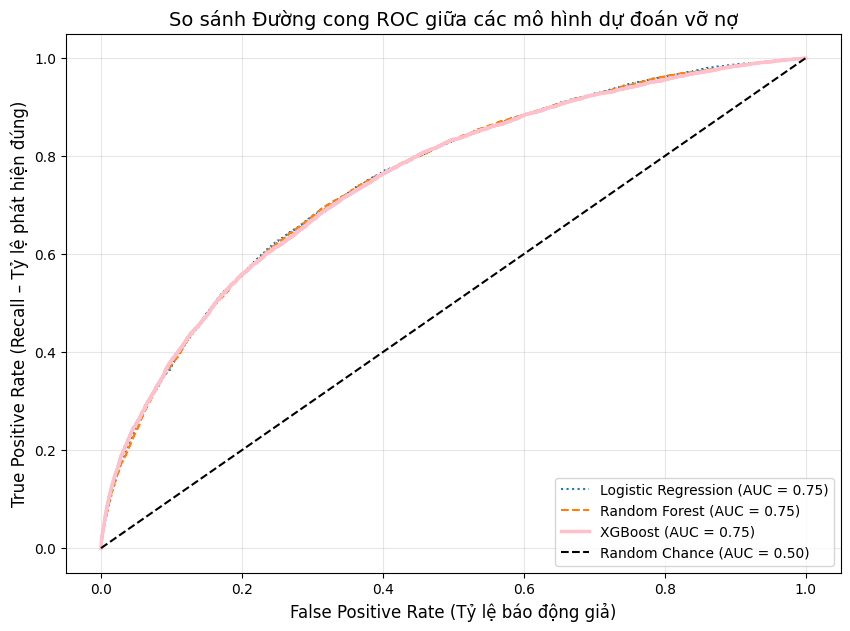

In [38]:
def evaluate_model(model_name, y_true, y_pred, y_proba):
    return {
        'Mô hình': model_name,
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred),
        'Recall': recall_score(y_true, y_pred),
        'F1-Score': f1_score(y_true, y_pred),
        'ROC-AUC': roc_auc_score(y_true, y_proba)
    }

# Tổng hợp kết quả đánh giá
results = []
results.append(evaluate_model('Logistic Regression', y_test, y_pred_lr, lr_proba))
results.append(evaluate_model('Random Forest', y_test, y_pred_rf, rf_proba))
results.append(evaluate_model('XGBoost', y_test, y_pred_xgb, xgb_proba))

df_comparison = pd.DataFrame(results).round(2)

print("BẢNG TỔNG HỢP KẾT QUẢ ĐÁNH GIÁ MÔ HÌNH:")
display(df_comparison)

# Lựa chọn mô hình tốt nhất (ưu tiên Recall & ROC-AUC)
best_model_row = df_comparison.sort_values(
    by=['Recall', 'ROC-AUC'],
    ascending=False
).iloc[0]

best_model_name = best_model_row['Mô hình']
print(f"MÔ HÌNH PHÙ HỢP NHẤT: {best_model_name}")

# VẼ ĐƯỜNG CONG ROC:

plt.figure(figsize=(10, 7))

fpr_lr, tpr_lr, _ = roc_curve(y_test, lr_proba)
plt.plot(fpr_lr, tpr_lr, linestyle=':',
         label=f'Logistic Regression (AUC = {roc_auc_score(y_test, lr_proba):.2f})')

fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_proba)
plt.plot(fpr_rf, tpr_rf, linestyle='--',
         label=f'Random Forest (AUC = {roc_auc_score(y_test, rf_proba):.2f})')

fpr_xgb, tpr_xgb, _ = roc_curve(y_test, xgb_proba)
plt.plot(fpr_xgb, tpr_xgb, linewidth=2.5, color='pink',
         label=f'XGBoost (AUC = {roc_auc_score(y_test, xgb_proba):.2f})')

plt.plot([0, 1], [0, 1], 'k--', label='Random Chance (AUC = 0.50)')

plt.title('So sánh Đường cong ROC giữa các mô hình dự đoán vỡ nợ', fontsize=14)
plt.xlabel('False Positive Rate (Tỷ lệ báo động giả)', fontsize=12)
plt.ylabel('True Positive Rate (Recall – Tỷ lệ phát hiện đúng)', fontsize=12)
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

Kết quả cho thấy cả ba mô hình đều đạt ROC-AUC = 0.75, chứng tỏ khả năng phân biệt giữa hai lớp (vỡ nợ và không vỡ nợ) ở mức khá và tương đương nhau.

Tuy nhiên, Logistic Regression có Recall cao nhất (0.70), nghĩa là mô hình phát hiện được nhiều trường hợp vỡ nợ nhất, phù hợp với mục tiêu bài toán quản trị rủi ro tín dụng – nơi việc bỏ sót khách hàng rủi ro gây hậu quả nghiêm trọng hơn so với báo động nhầm.

Mặc dù Random Forest đạt Accuracy và F1-Score nhỉnh hơn, nhưng Recall thấp hơn đáng kể. Do đó, xét theo tiêu chí ưu tiên Recall và ROC-AUC, Logistic Regression được lựa chọn là mô hình phù hợp nhất cho bài toán.

## **7. Giải thích mô hình Logistic Regression bằng SHAP (XAI)**

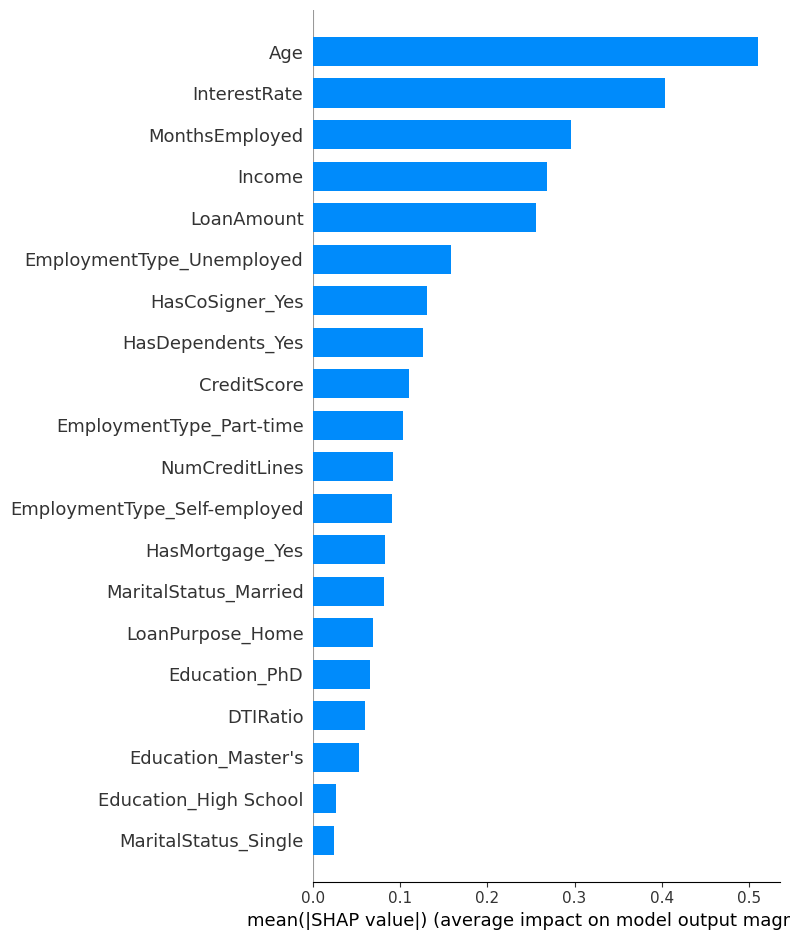

In [26]:
# Lấy 1 mẫu nhỏ cho SHAP
X_shap = X_train.sample(1000, random_state=42)

# Dùng LinearExplainer cho Logistic Regression
explainer = shap.LinearExplainer(lr_model, X_shap)

# Tính SHAP values
shap_values = explainer.shap_values(X_shap)

# Summary plot
shap.summary_plot(
    shap_values,
    X_shap,
    feature_names=X_shap.columns,
    plot_type="bar"
)

**Nhận xét:**
* Age là biến có mức độ ảnh hưởng lớn nhất đến đầu ra mô hình, cho thấy độ tuổi đóng vai trò quan trọng trong việc dự đoán khả năng vỡ nợ.

* InterestRate, MonthsEmployed, Income và LoanAmount cũng có ảnh hưởng đáng kể, phản ánh đúng logic tài chính: lãi suất cao, thu nhập thấp, khoản vay lớn hoặc thời gian làm việc ngắn làm tăng rủi ro.

* Các biến liên quan đến tình trạng việc làm (Unemployed, Part-time, Self-employed) và bảo lãnh (HasCoSigner) có tác động trung bình, góp phần điều chỉnh xác suất dự đoán.

* Các biến nhân khẩu học sau khi one-hot encoding như trình độ học vấn và tình trạng hôn nhân có mức ảnh hưởng thấp, cho thấy chúng ít quyết định hơn so với các yếu tố tài chính.
#####**==> Mô hình Logistic Regression chủ yếu dựa vào các biến tài chính cốt lõi, và kết quả giải thích bằng SHAP là hợp lý, nhất quán với thực tế nghiệp vụ tín dụng, đồng thời giúp tăng tính minh bạch của mô hình.**